# Statistical classifier experiments

3 experiments using the existing BIC estimator, with binary symbols, candidate orders 0–6 and the same `N - 6` targets for every candidate. 


In [ ]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.generate_data import (
    generate_zero_order_processes, generate_first_order_processes,
    generate_k_order_processes, generate_infinite_order_processes,
)
from src.statistical import estimate_markov_order

SEED = 42
MAX_ORDER = 6
LENGTHS = [500, 1000, 5000, 10000, 50000]
REPEATS = 60
N_TABLES = 6 #number of tables to generate for each order
EPSILONS = [0, 0.01, 0.02, 0.05, 0.10, 0.20]
OUT = ROOT / "data" / "statistical_experiments"
OUT.mkdir(parents=True, exist_ok=True)
rows = []

## Experiment 1 — Recovery vs. sequence length

Keep six tables per order fixed across lengths. For order 1, the existing generator supplies three weak and three strong tables. For orders 2–5, use its Dirichlet tables; for order 0, use its i.i.d. probability vectors. A small sampler is needed to reuse fixed tables, because the existing generators draw new tables on each call. It uses the same binary history encoding.

In [ ]:
_, iid = generate_zero_order_processes(N_TABLES, sequence_length=1, seed=SEED)
_, _, first, _ = generate_first_order_processes(N_TABLES, sequence_length=1, seed=SEED + 1)
tables = {0: iid[:, None, :], 1: first}
for k in range(2, 6):
    _, tables[k], _ = generate_k_order_processes(
        k, num_processes=N_TABLES, sequence_length=k, seed=SEED + k
    )
for k, bank in tables.items():
    assert np.all(bank > 0) and np.allclose(bank.sum(axis=-1), 1)
    if k:
        # Histories differing only in their oldest bit must differ somewhere.
        assert all(np.any(table[:2**(k-1)] != table[2**(k-1):]) for table in bank) #validate that the tables are valid Markov transition matrices


def sample_binary(table, order, n, seed):
    rng = np.random.default_rng(seed)
    if order == 0:
        return (rng.random(n) < table[0, 1]).astype(int) # iid processes with the same probability of 1 as the table
    sequence = np.empty(n, dtype=int)
    sequence[:order] = rng.integers(2, size=order)
    history = 0
    for symbol in sequence[:order]:
        history = 2 * history + int(symbol)
    uniforms = rng.random(n - order)
    for t, u in enumerate(uniforms, start=order):
        symbol = int(u < table[history, 1])
        sequence[t] = symbol
        history = (2 * history + symbol) % (2**order)
    return sequence #generate 6 Markov processes of order 0 to 5, sample sequences from them, and estimate their order using the estimate_markov_order function. The results are stored in a list of dictionaries for later analysis.


def record(sequence, experiment, process, true_order, n, epsilon, rep, seed, **extra):
    result = estimate_markov_order(sequence, max_order=MAX_ORDER, m=2)
    assert result["n_eff"] == n - MAX_ORDER
    rows.append(dict(experiment=experiment, process=process, true_order=true_order,
                     N=n, epsilon=epsilon, replicate=rep,
                     estimated_order=result["estimated_order"], seed=seed, **extra))


for k in range(6):
    for ni, n in enumerate(LENGTHS):
        for rep in range(REPEATS):
            table_id = rep % N_TABLES
            seed = SEED + 100_000 + k * 10_000 + ni * 100 + rep
            sequence = sample_binary(tables[k][table_id], k, n, seed)
            record(sequence, 1, f"order_{k}", k, n, None, rep, seed, table_id=table_id)
    print(f"Completed finite order {k}", flush=True)

Completed finite order 0


Completed finite order 1


Completed finite order 2


Completed finite order 3


Completed finite order 4


Completed finite order 5


## Experiment 2 — Infinite memory, finite estimates

Use the existing Even Process and SNS generator, which starts in stationarity and draws `p` uniformly from [0.2, 0.8). Each seed generates one independent sequence from each family. Save `p` in the results. The heatmaps show selection frequencies, not recovery accuracy: a finite candidate search cannot certify infinite order.

In [ ]:
for ni, n in enumerate(LENGTHS):
    for rep in range(REPEATS):
        seed = SEED + 200_000 + ni * 100 + rep
        batch = generate_infinite_order_processes(num_processes=2, sequence_length=n, seed=seed)
        for sequence, family, p in zip(batch["sequences"], batch["families"], batch["p"]):
            record(sequence, 2, str(family), np.inf, n, None, rep, seed, p=float(p))
    print(f"Completed infinite-memory examples, N={n}", flush=True)
    #we genereate 2 inf memory processes for each length, and repeat this for REPEATS times. The results are recorded in the rows list.

Completed infinite-memory examples, N=500


Completed infinite-memory examples, N=1000


Completed infinite-memory examples, N=5000


Completed infinite-memory examples, N=10000


Completed infinite-memory examples, N=50000


## Experiment 3 — Weak dependence vs. sample size

Use $Q_\varepsilon = \begin{pmatrix}0.5+\varepsilon & 0.5-\varepsilon \\ 0.5-\varepsilon & 0.5+\varepsilon\end{pmatrix}$ and a uniform initial symbol, which is stationary. The true order is 0 at zero and 1 for every positive tested epsilon. Plot the fraction selecting order 1; the zero row measures false positives for order 1. We also report the fraction selecting any positive order for that control.

In [ ]:
for ei, epsilon in enumerate(EPSILONS):
    table = np.array([[0.5 + epsilon, 0.5 - epsilon],
                      [0.5 - epsilon, 0.5 + epsilon]])
    for ni, n in enumerate(LENGTHS):
        for rep in range(REPEATS):
            seed = SEED + 300_000 + ei * 10_000 + ni * 100 + rep
            sequence = sample_binary(table, 1, n, seed)
            record(sequence, 3, "symmetric_chain", int(epsilon > 0), n, epsilon, rep, seed)
    print(f"Completed epsilon={epsilon}", flush=True)

results = pd.DataFrame(rows)
assert len(results) == 3 * 6 * len(LENGTHS) * REPEATS - 4 * len(LENGTHS) * REPEATS
assert results.groupby(["experiment", "process", "N", "epsilon"], dropna=False).size().eq(REPEATS).all()
assert results["estimated_order"].between(0, MAX_ORDER).all()
results.to_csv(OUT / "results.csv", index=False)
settings = dict(seed=SEED, max_order=MAX_ORDER, lengths=LENGTHS, repeats=REPEATS,
                epsilon=EPSILONS, finite_tables={str(k): v.tolist() for k, v in tables.items()},
                finite_initialization="uniform history", infinite_p_range=[0.2, 0.8],
                infinite_initialization="stationary",
                versions=dict(numpy=np.__version__, pandas=pd.__version__))
(OUT / "settings.json").write_text(json.dumps(settings, indent=2))
print(f"Saved {len(results)} runs to {OUT}")
# for each epsilon conduct len(length)*repeat experiments

Completed epsilon=0


Completed epsilon=0.01


Completed epsilon=0.02


Completed epsilon=0.05


Completed epsilon=0.1


Completed epsilon=0.2


Saved 4200 runs to /Users/egorpanteleev/markov-order-classifier/data/statistical_experiments


## Figures and aggregated results

Every plotted proportion uses 60 repetitions. At a proportion near 0.5, Monte Carlo standard error can be about 0.065; small differences should not be overinterpreted. Experiment 1 also depends on the six sampled tables per order.

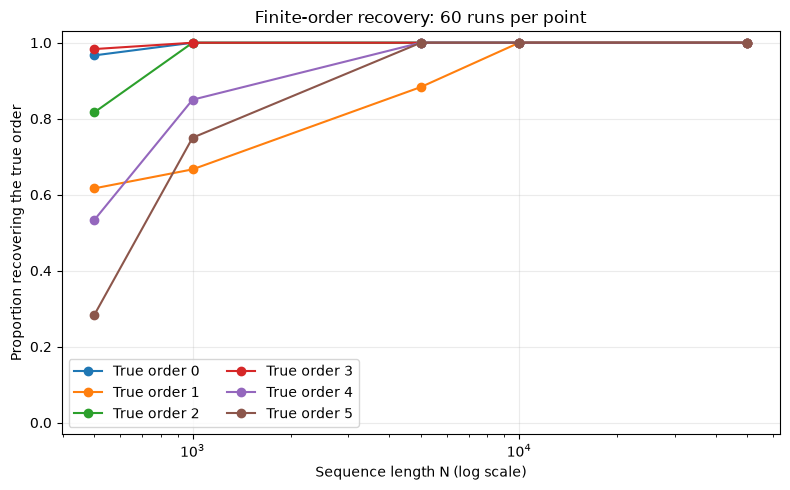

N,500,1000,5000,10000,50000
true_order,,,,,
0.0,0.967,1.000,1.000,1.0,1.0
1.0,0.617,0.667,0.883,1.0,1.0
2.0,0.817,1.000,1.000,1.0,1.0
3.0,0.983,1.000,1.000,1.0,1.0
4.0,0.533,0.850,1.000,1.0,1.0
5.0,0.283,0.750,1.000,1.0,1.0


In [ ]:
finite = results[results.experiment == 1].copy()
finite["correct"] = finite.estimated_order == finite.true_order
accuracy = finite.groupby(["true_order", "N"])["correct"].mean().unstack("N")
accuracy.to_csv(OUT / "recovery_accuracy.csv")
fig, ax = plt.subplots(figsize=(8, 5))
for k, row in accuracy.iterrows():
    ax.plot(LENGTHS, row, marker="o", label=f"True order {int(k)}")
ax.set(xscale="log", xlabel="Sequence length N (log scale)",
       ylabel="Proportion recovering the true order", ylim=(-0.03, 1.03),
       title="Finite-order recovery: 60 runs per point")
ax.legend(ncol=2)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "recovery_accuracy.png", dpi=150)
plt.show()
display(accuracy.round(3))

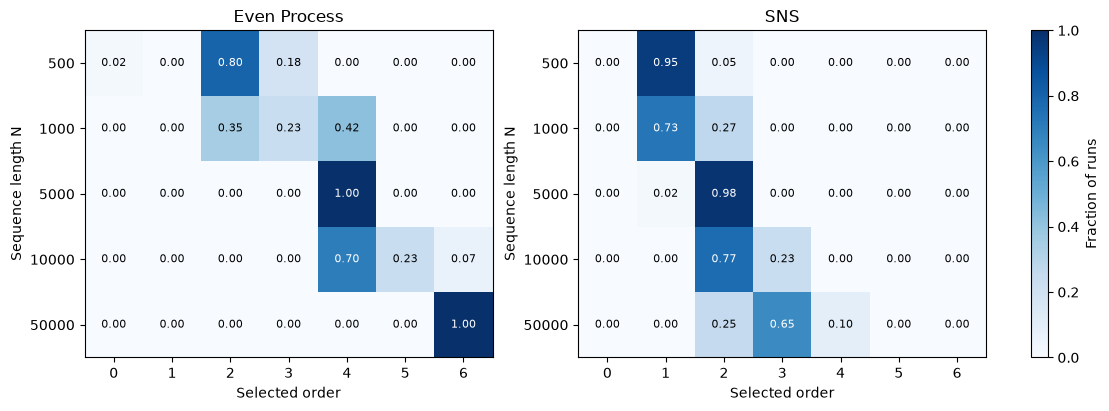

In [6]:
infinite = results[results.experiment == 2]
frequencies = (infinite.groupby(["process", "N", "estimated_order"]).size() / REPEATS)
frequencies.rename("fraction").to_csv(OUT / "infinite_selection_frequencies.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, family in zip(axes, ["even", "sns"]):
    matrix = (frequencies.loc[family].unstack("estimated_order", fill_value=0)
              .reindex(index=LENGTHS, columns=range(MAX_ORDER + 1), fill_value=0))
    im = ax.imshow(matrix, vmin=0, vmax=1, aspect="auto", cmap="Blues")
    ax.set(xticks=range(MAX_ORDER + 1), yticks=range(len(LENGTHS)),
           yticklabels=LENGTHS, xlabel="Selected order", ylabel="Sequence length N",
           title="Even Process" if family == "even" else "SNS")
    for i in range(len(LENGTHS)):
        for j in range(MAX_ORDER + 1):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center",
                    color="white" if matrix.iloc[i, j] > 0.5 else "black", fontsize=8)
fig.colorbar(im, ax=axes, label="Fraction of runs")
fig.savefig(OUT / "infinite_selection.png", dpi=150)
plt.show()

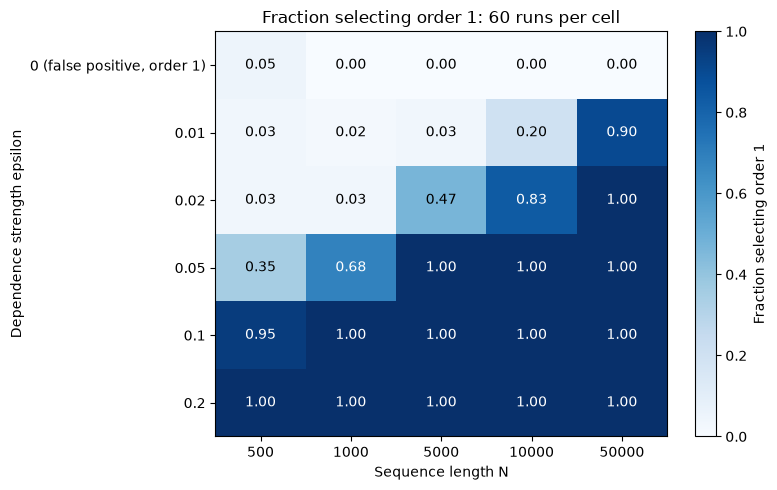

N,500,1000,5000,10000,50000
epsilon,,,,,
0.00,0.050,0.000,0.000,0.000,0.0
0.01,0.033,0.017,0.033,0.200,0.9
0.02,0.033,0.033,0.467,0.833,1.0
0.05,0.350,0.683,1.000,1.000,1.0
0.10,0.950,1.000,1.000,1.000,1.0
0.20,1.000,1.000,1.000,1.000,1.0


In [7]:
weak = results[results.experiment == 3].copy()
weak["selected_one"] = weak.estimated_order == 1
selection = weak.groupby(["epsilon", "N"])["selected_one"].mean().unstack("N")
selection.to_csv(OUT / "dependence_detection.csv")
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(selection, vmin=0, vmax=1, aspect="auto", cmap="Blues")
ax.set(xticks=range(len(LENGTHS)), xticklabels=LENGTHS,
       yticks=range(len(EPSILONS)),
       yticklabels=["0 (false positive, order 1)"] + [str(e) for e in EPSILONS[1:]],
       xlabel="Sequence length N", ylabel="Dependence strength epsilon",
       title="Fraction selecting order 1: 60 runs per cell")
for i in range(len(EPSILONS)):
    for j in range(len(LENGTHS)):
        ax.text(j, i, f"{selection.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if selection.iloc[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, label="Fraction selecting order 1")
fig.tight_layout()
fig.savefig(OUT / "dependence_detection.png", dpi=150)
plt.show()
display(selection.round(3))